# IBM HR Analytics Employee Attrition & Performance

**Source:** [IBM HR Analytics Employee Attrition & Performance on Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)

## Dataset overview

This fictional dataset was created by IBM data scientists to explore patterns associated with employee attrition.

Example questions to investigate:

- How does distance from home vary by job role and attrition status?
- How does average monthly income differ by education level and attrition status?

## Category codes

The following tables explain the numeric codes used in the dataset.

### Education

| Code | Education level |
| --- | --- |
| 1 | Below College |
| 2 | College |
| 3 | Bachelor |
| 4 | Master |
| 5 | Doctor |

### Satisfaction and involvement

These four columns share the same rating scale:

- `EnvironmentSatisfaction`
- `JobInvolvement`
- `JobSatisfaction`
- `RelationshipSatisfaction`

| Code | Rating |
| --- | --- |
| 1 | Low |
| 2 | Medium |
| 3 | High |
| 4 | Very High |

### Performance rating (`PerformanceRating`)

| Code | Rating |
| --- | --- |
| 1 | Low |
| 2 | Good |
| 3 | Excellent |
| 4 | Outstanding |

### Work–life balance (`WorkLifeBalance`)

| Code | Rating |
| --- | --- |
| 1 | Bad |
| 2 | Good |
| 3 | Better |
| 4 | Best |

### Target column (`Attrition`)

**Employee attrition** means employees leaving the company. `Attrition` is the target column: the outcome a classification model aims to predict using the other employee attributes.

| Value | Meaning |
| --- | --- |
| `Yes` | The employee left the company. |
| `No` | The employee stayed with the company. |

This is a **binary classification** target because it has two possible classes. The column records whether an employee left, but does not specify why they left.

An **attrition rate** is the percentage of employees in a group whose `Attrition` value is `Yes`.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("./data/week_3_WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Show me a breakdown of distance from home by job role and attrition

In [6]:
breakdown = (
    df.groupby(["JobRole", "Attrition"])["DistanceFromHome"]
    .agg(
        Employees="count",
        Mean="mean",
        Median="median",
        Minimum="min",
        Maximum="max",
    )
)

display(
    breakdown.reset_index()
    .style
    .hide(axis="index")
    .format({"Mean": "{:.2f}", "Median": "{:.1f}"})
    .set_caption("Distance from home by job role and attrition")
)

JobRole,Attrition,Employees,Mean,Median,Minimum,Maximum
Healthcare Representative,No,122,9.20,7.0,1,29
Healthcare Representative,Yes,9,17.67,20.0,2,29
Human Resources,No,40,6.60,3.5,1,26
Human Resources,Yes,12,13.42,15.0,1,23
Laboratory Technician,No,197,9.33,7.0,1,29
Laboratory Technician,Yes,62,9.66,7.0,1,29
Manager,No,97,7.93,4.0,1,29
Manager,Yes,5,10.00,2.0,2,29
Manufacturing Director,No,135,9.53,7.0,1,29
Manufacturing Director,Yes,10,8.80,7.5,1,23


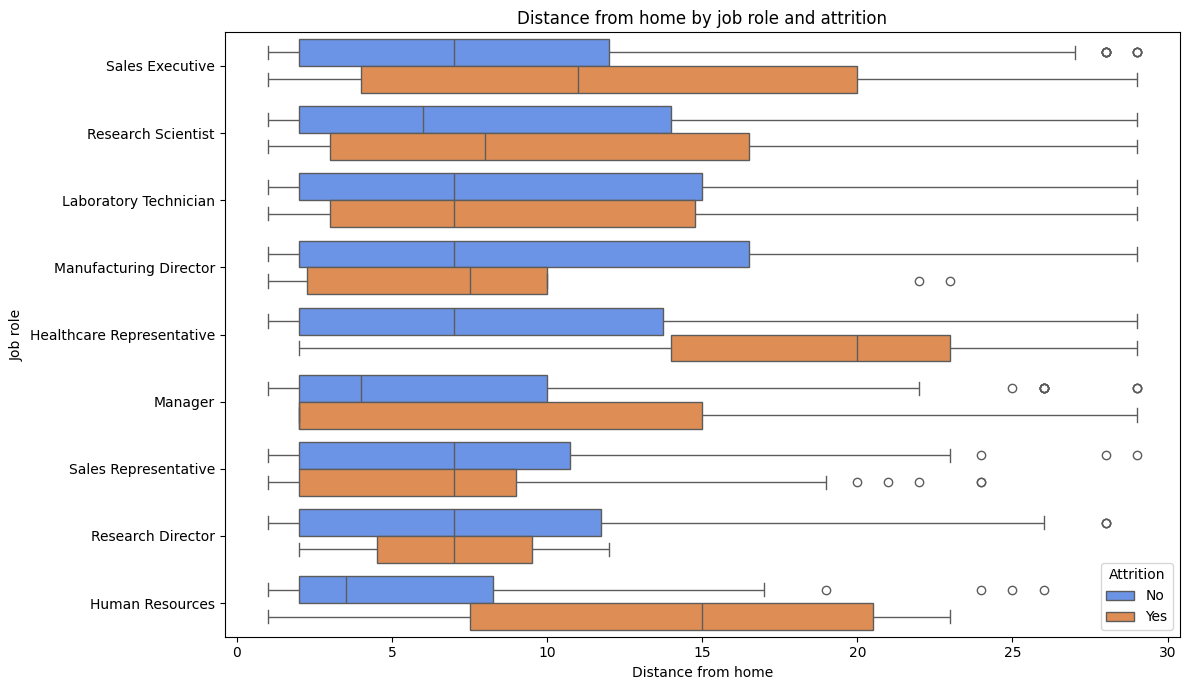

In [7]:
fig, ax = plt.subplots(figsize=(12, 7))

sns.boxplot(
    data=df,
    x="DistanceFromHome",
    y="JobRole",
    hue="Attrition",
    hue_order=["No", "Yes"],
    ax=ax,
)

ax.set_title("Distance from home by job role and attrition")
ax.set_xlabel("Distance from home")
ax.set_ylabel("Job role")
ax.legend(title="Attrition")
fig.tight_layout()
plt.show()

Compare average monthly income by education and attrition

In [8]:
education_labels = {
    1: "Below College",
    2: "College",
    3: "Bachelor",
    4: "Master",
    5: "Doctor",
}

income_breakdown = (
    df.groupby(["Education", "Attrition"])["MonthlyIncome"]
    .agg(Employees="count", AverageMonthlyIncome="mean")
    .reset_index()
)

income_breakdown["Education"] = (
    income_breakdown["Education"].map(education_labels)
)

display(
    income_breakdown.style
    .hide(axis="index")
    .format({"AverageMonthlyIncome": "{:,.2f}"})
    .set_caption("Average monthly income by education and attrition")
)

Education,Attrition,Employees,AverageMonthlyIncome
Below College,No,139,"5,926.13"
Below College,Yes,31,"4,360.16"
College,No,238,"6,586.06"
College,Yes,44,"4,282.55"
Bachelor,No,473,"6,882.92"
Bachelor,Yes,99,"4,770.24"
Master,No,340,"7,087.81"
Master,Yes,58,"5,335.16"
Doctor,No,43,"8,559.91"
Doctor,Yes,5,"5,850.20"


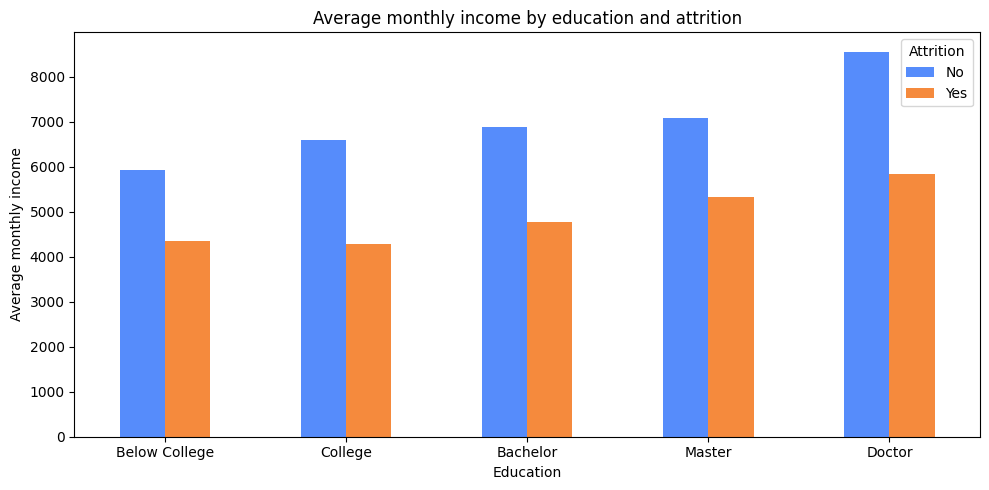

In [9]:
income_comparison = income_breakdown.pivot(
    index="Education",
    columns="Attrition",
    values="AverageMonthlyIncome",
).reindex(education_labels.values())

ax = income_comparison.plot.bar(
    figsize=(10, 5),
    rot=0,
    title="Average monthly income by education and attrition",
)

ax.set_xlabel("Education")
ax.set_ylabel("Average monthly income")
ax.legend(title="Attrition")
plt.tight_layout()
plt.show()

## Conclusion

In this fictional IBM employee dataset, the comparisons show a consistent income pattern and a mixed distance pattern:

- **Monthly income:** Employees who left had lower average monthly incomes at every education level. For example, employees with a Bachelor's education who left earned an average of **4,770.24**, compared with **6,882.92** for those who stayed.
- **Distance from home:** Employees who left lived farther from work on average in **6 of the 9 job roles**. The opposite pattern occurred for Manufacturing Directors, Research Directors, and Sales Representatives.
- **Group sizes:** Some averages are based on very few employees who left, including **2 Research Directors** and **5 Managers**. These comparisons should be interpreted cautiously.

Overall, lower income and greater distance from home are associated with attrition in these comparisons, but the distance pattern is not consistent across all job roles. These results **do not establish that either factor causes employees to leave**. Other attributes, such as seniority, job role, and overtime, may help explain the differences.

These tables compare average income and distance between employees who left and those who stayed; they do not directly measure attrition rates within income or distance bands. A useful next step is to calculate the **percentage of employees who left within each income and distance band**, alongside the number of employees in each group.

The findings describe this fictional dataset and should not be treated as evidence about real employees.